## Question 2


exact mean 1.85 sd 157.18 99 percent quantile 623.26
linear mean -105.02 sd 0.0 99 percent quantile -105.02
quadratic mean 1.37 sd 151.34 99 percent quantile 604.47


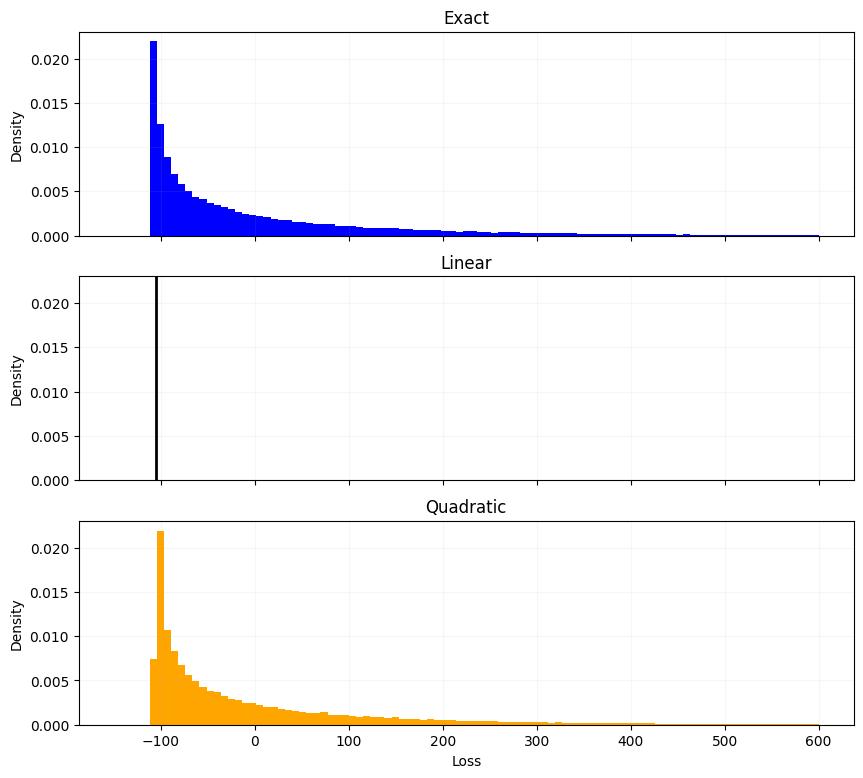

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu = 0.16905
sigma = 0.4907
r = 0.0011888
T = 0.291667
horizon = 10/252
S0 = 152.51
K = 170.0
puts = 100
trials = 100000


def put_price(time, spot):
    tau = T - time
    d1 = (np.log(spot/K) + (r + 0.5*sigma**2)*tau)/(sigma*np.sqrt(tau))
    d2 = d1 - sigma*np.sqrt(tau)
    return spot*(norm.cdf(d1) - 1) + K*np.exp(-r*tau)*(1 - norm.cdf(d2))


d1 = (np.log(S0/K) + (r + 0.5*sigma**2)*T)/(sigma*np.sqrt(T))
d2 = d1 - sigma*np.sqrt(T)
put_now = put_price(0, S0)
delta = norm.cdf(d1) - 1
gamma = norm.pdf(d1)/(S0*sigma*np.sqrt(T))
theta = -sigma*S0*norm.pdf(d1)/(2*np.sqrt(T)) + K*r*np.exp(-r*T)*(1 - norm.cdf(d2))

generator = np.random.default_rng(42)
returns = generator.normal((mu - 0.5*sigma**2)*horizon, sigma*np.sqrt(horizon), trials)

decay = puts*theta*horizon
exact = puts*(delta*S0*(1 - np.exp(returns))
              - (put_now - put_price(horizon, S0*np.exp(returns))))
linear = np.full(trials, decay)
quadratic = decay + 0.5*puts*gamma*S0**2*returns**2

for name, losses in [("exact", exact), ("linear", linear), ("quadratic", quadratic)]:
    print(name, "mean", round(losses.mean(), 2),
          "sd", round(losses.std(ddof=1), 2),
          "99 percent quantile", round(np.quantile(losses, 0.99), 2))

bins = np.linspace(-150, 600, 100)
figure, panels = plt.subplots(3, 1, figsize=(10, 9), sharex=True, sharey=True)
panels[0].hist(exact, bins=bins, density=True, color="blue")
panels[0].set_title("Exact")
panels[1].axvline(decay, color="black", linewidth=2)
panels[1].set_title("Linear")
panels[2].hist(quadratic, bins=bins, density=True, color="orange")
panels[2].set_title("Quadratic")
for panel in panels:
    panel.set_ylabel("Density")
    panel.grid(alpha=0.1)
panels[2].set_xlabel("Loss")
plt.show()